# QLearning with ANN Approximator

In [30]:
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt

In [31]:
state = torch.tensor([[-1.0] , [0.0] , [1.0] , [2.0] , [3.0] , [4.0]] , dtype=torch.float)
Q_target = torch.tensor([[-3.0] , [-1.5] , [2.0] , [3.0] , [4.0] , [7.0]] , dtype=torch.float)
print(state.shape , Q_target.shape)

torch.Size([6, 1]) torch.Size([6, 1])


In [32]:
layer1=nn.Linear(1 , 1 , bias = True)
relu = nn.ReLU()
layer2=nn.Linear(1 , 1 , bias = True)
relu = nn.ReLU()
layer3=nn.Linear(1 , 1 , bias = True)
model = nn.Sequential(layer1 , relu ,  layer2 , relu , layer3)

In [33]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters() , lr = 0.01)

In [34]:
for i in range(100):
  Q_pred = model(state)
  loss_val=loss_fn(Q_pred , Q_target)
  optimizer.zero_grad()
  loss_val.backward()
  optimizer.step()
  print(loss_val.item())

14.797030448913574
14.652702331542969
14.514327049255371
14.381632804870605
14.247627258300781
14.101607322692871
13.96125316619873
13.825470924377441
13.693263053894043
13.56369686126709
13.435860633850098
13.308836936950684
13.181662559509277
13.053303718566895
12.922618865966797
12.788325309753418
12.648932456970215
12.50272274017334
12.347649574279785
12.181285858154297
12.000699043273926
11.80237865447998
11.5820894241333
11.334784507751465
11.054509162902832
10.734444618225098
10.367104530334473
9.944931983947754
9.461487770080566
8.913521766662598
8.304113388061523
7.646547317504883
6.967552185058594
6.307018280029297
5.710845947265625
5.216675281524658
4.839256763458252
4.566403865814209
4.372671604156494
4.220069885253906
4.093883037567139
3.978395462036133
3.8704097270965576
3.7673046588897705
3.667804479598999
3.571383476257324
3.4777984619140625
3.386906385421753
3.2986032962799072
3.212801694869995
3.1294212341308594
3.048389434814453
2.969636917114258
2.893099546432495
2.

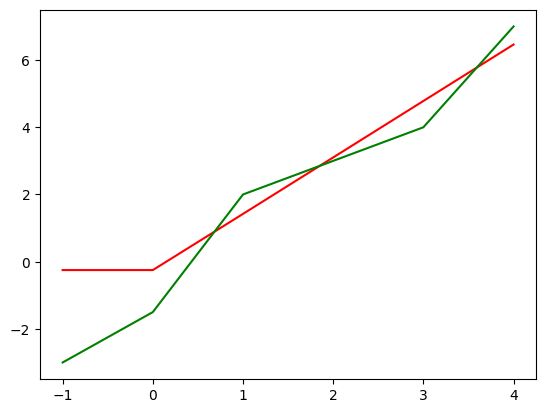

In [35]:
plt.plot(state.detach().numpy() , Q_pred.detach().numpy() , color = 'red')
plt.plot(state.detach().numpy() , Q_target.detach().numpy() , color = 'green')

In [36]:
class QEstimator(nn.Module): # ers barri
  def __init__(self , input_dim, hidden_dim = 16 , output_dim =1):
    super(QEstimator, self).__init__()
    layer1=nn.Linear(input_dim , hidden_dim , bias = True)
    relu = nn.ReLU()
    layer2=nn.Linear(hidden_dim , output_dim , bias = True)
    self.estimator = nn.Sequential(layer1 , relu , layer2 )
  def forward(self , state):
    state = torch.tensor(state) # shabih numpy array ama shekl mord estefade baray model ha dar tourch
    q_pred = self.estimator(state)
    return q_pred


In [44]:
class Qlearner:
  def __init__(self, state_size , action_size , learning_rate=0.01 , discount_factor=0.95 , epsilon =0.1):
    self.state_size = state_size
    self.action_size = action_size
    self.learning_rate = learning_rate
    self.discount_factor = discount_factor
    self.epsilon = epsilon

    self.model = QEstimator(state_size , output_dim = action_size)
    self.loss_fn = nn.MSELoss()
    self.optimizer = torch.optim.SGD(self.model.parameters() , lr = learning_rate)
    self.buffer = []

  def select_action(self , state):
    q_values = self.model(state).detach().numpy() #khoruji model besurat tensor ast. an ra b numpy tabdil mikonim
    p=np.random.rand()
    if p<self.epsilon:
      action = np.random.randint(0 , self.action_size)
    else:
      action = np.argmax(q_values)
    return action
  def add_buffer(self , state , action , reward , next_state , done):
    self.buffer.append([state , action , reward , next_state , done])

  def update(self , batch_size=16):
    sampled_inds = np.random.choice(len(self.buffer) , min(batch_size , len(self.buffer)) , replace=False).ravel()
    minibatch = [self.buffer[i] for i in sampled_inds]

    states =[]
    targets =[]

    for sample in minibatch:
      state , action , reward , next_state , done = sample
      if done:
        target = reward
      else:
        target = reward + self.discount_factor * torch.max(self.model(next_state)).item()# max giri roy pishbini model az value be ezeya hame action haye momken dar state bad

      states.append(torch.tensor(state))
      target_q_values = self.model(state).detach().numpy() #q-val be ezay tamam action haye momken dar state feli
      target_q_values[action] = target # q-val action entekhabi ra ba target mohasebe shode jaygozari mikonim
      # 2 bordar  k hardu pred model hastand yekishon be ezay action entekhabi meghdar target ro dare va dar bordar dig b rezaye hamun action meghdar
      # meghdar pred va vaghti in do bordar ro az ham kam konim be ezaye hame action ha gheir az action entekhabi k ekhtelaf pred va target hast sefr mishe
      targets.append(torch.tensor(target_q_values, dtype=torch.float32))

    #tabdil list ha be tensor
    states = torch.vstack(states) # minibatch az experience ha
    targets = torch.vstack(targets) # target moadel action entekhabi b ezaye state ha

    self.optimizer.zero_grad() #gradiyan haye ghabli 0
    loss = self.loss_fn(self.model(states) , targets)
    loss.backward()
    self.optimizer.step()



In [45]:
# env
import gymnasium as gym
import numpy as np

n_episodes = 1000
total_reward =[]
env = gym.make('CartPole-v1')
agent = Qlearner(env.observation_space._shape[0] , env.action_space.n)

for i in range(n_episodes):
    state , info = env.reset()
    episode_rewards=[]
    while True: # gam haye yek episode
        action=agent.select_action(state)
        next_state, reward, terminated, truncated, info = env.step(action)
        agent.add_buffer(state , action , reward , next_state , terminated)
        episode_rewards.append(reward)
        state=next_state
        if terminated:
            break
    agent.update(batch_size=16)
    total_reward.append(np.sum(episode_rewards))

/tmp/ipykernel_2014/3602871158.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  state = torch.tensor(state) # shabih numpy array ama shekl mord estefade baray model ha dar tourch


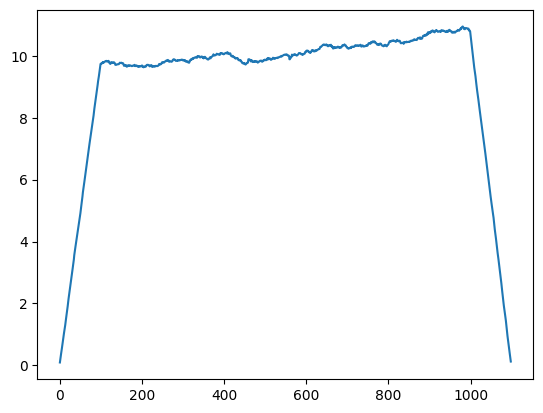

In [46]:
import matplotlib.pyplot as plt
plt.plot(np.convolve(total_reward, np.ones(100)/100))